Use Neural Network to classify the images from **CIFAR-10** dataset

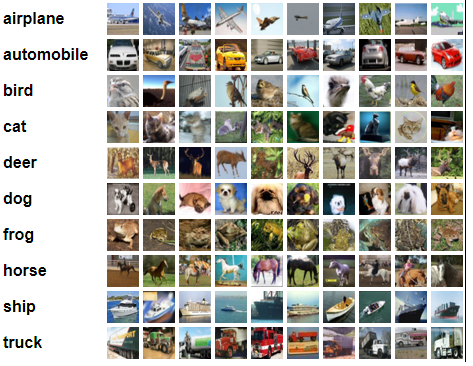

#Select **T4 GPU** (free) in Cobal Notebook settings to speed up the training

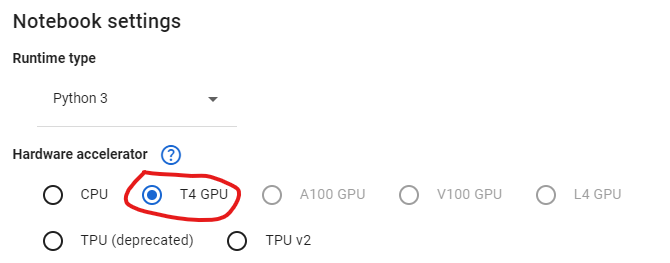

In [1]:
#@title Execute this block to import TensorFlow deep learning library

import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.applications import VGG16
from tensorflow.keras.utils import plot_model

# Predict individual image
def predictOneImage(x_test, y_test, ans, p_index):
  first_image = x_test[p_index]
  plt.imshow(first_image)
  plt.show()

  count = 0
  for a in ans[p_index]:
      print(labels[count], "=", round(a*100, 2))
      count = count + 1

  print("------------------")
  print("True Label:", labels[y_test[p_index][0]])

In [2]:
#@title Downloand the CIFAR-10 labelled data, split them into train and test sets

# https://www.cs.toronto.edu/~kriz/cifar.html
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

labels = {
    0: "plane",
    1: "car  ",
    2: "bird ",
    3: "cat  ",
    4: "deer ",
    5: "dog  ",
    6: "frog ",
    7: "horse",
    8: "ship ",
    9: "truck",
}

train_size, test_size = x_train.shape[0], x_test.shape[0]
height, width, depth = x_train.shape[1], x_train.shape[2], x_train.shape[3]

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2784s 16us/step
x_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
x_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


[[[ 59  62  63]
  [ 43  46  45]
  [ 50  48  43]
  ...
  [158 132 108]
  [152 125 102]
  [148 124 103]]

 [[ 16  20  20]
  [  0   0   0]
  [ 18   8   0]
  ...
  [123  88  55]
  [119  83  50]
  [122  87  57]]

 [[ 25  24  21]
  [ 16   7   0]
  [ 49  27   8]
  ...
  [118  84  50]
  [120  84  50]
  [109  73  42]]

 ...

 [[208 170  96]
  [201 153  34]
  [198 161  26]
  ...
  [160 133  70]
  [ 56  31   7]
  [ 53  34  20]]

 [[180 139  96]
  [173 123  42]
  [186 144  30]
  ...
  [184 148  94]
  [ 97  62  34]
  [ 83  53  34]]

 [[177 144 116]
  [168 129  94]
  [179 142  87]
  ...
  [216 184 140]
  [151 118  84]
  [123  92  72]]]


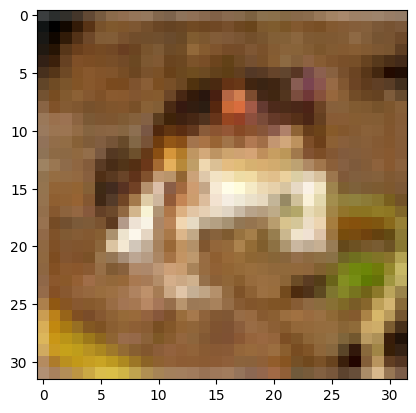

Label: frog 


In [3]:
#@title Visualize the training data. Pick one sample from the training data set

training_sample = 0 #@param {type:"integer"}

print(x_train[training_sample])
first_image = x_train[training_sample]
plt.imshow(first_image)
plt.show()

print("Label:", labels[y_train[training_sample][0]])

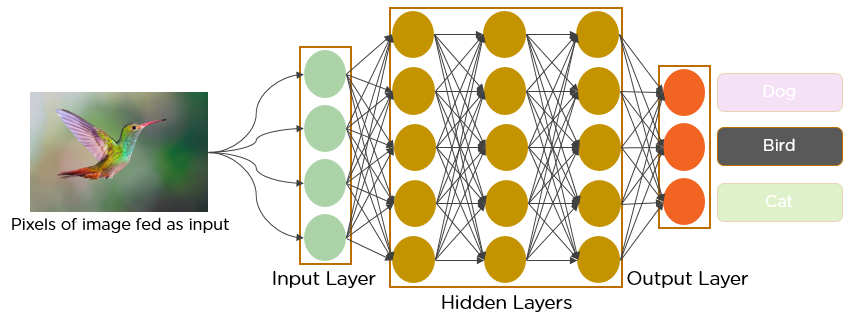

In [4]:
#@title Convert the image pixels to neural network input vector format

# For Dense Neural Network
# reshape the 32x32x3 pixels to a 3072 array
# and normalize the number by 255

dim = height * width * depth
x_trainp = x_train.reshape(train_size, dim)
x_testp = x_test.reshape(test_size, dim)

normalize = 255
x_trainp = x_trainp.astype('float32') / normalize
x_testp = x_testp.astype('float32') / normalize

print(x_trainp.shape[0], 'train samples')
print(x_testp.shape[0], 'test samples')

50000 train samples
10000 test samples


In [5]:
# Look at one example of reshaped (flatten) and normalized training data
print(*x_trainp[0])

0.23137255 0.24313726 0.24705882 0.16862746 0.18039216 0.1764706 0.19607843 0.1882353 0.16862746 0.26666668 0.21176471 0.16470589 0.38431373 0.28627452 0.20392157 0.46666667 0.35686275 0.24705882 0.54509807 0.41960785 0.29411766 0.5686275 0.43137255 0.3137255 0.58431375 0.45882353 0.34901962 0.58431375 0.47058824 0.3647059 0.5137255 0.40392157 0.3019608 0.49019608 0.3882353 0.29803923 0.5568628 0.4509804 0.35686275 0.5647059 0.4392157 0.3372549 0.5372549 0.4117647 0.30980393 0.5058824 0.38039216 0.2784314 0.5372549 0.41568628 0.30980393 0.5254902 0.41568628 0.29803923 0.4862745 0.38039216 0.2509804 0.54509807 0.44313726 0.30588236 0.54509807 0.4392157 0.29411766 0.52156866 0.4117647 0.27058825 0.53333336 0.4117647 0.2901961 0.54509807 0.42352942 0.3019608 0.59607846 0.47058824 0.34901962 0.6392157 0.5137255 0.39215687 0.65882355 0.53333336 0.42352942 0.62352943 0.5058824 0.4 0.61960787 0.50980395 0.40784314 0.61960787 0.5176471 0.42352942 0.59607846 0.49019608 0.4 0.5803922 0.4862745 0

In [6]:
#@title Convert the Output (image label) to neural network vector format (one-hot encoding)

num_classes = 10

y_trainp = keras.utils.to_categorical(y_train, num_classes)
y_testp = keras.utils.to_categorical(y_test, num_classes)


print("one-hot encoding: ", labels)

print(labels[y_train[0][0]], ": ", y_trainp[0])
print(labels[y_train[1][0]], ": ", y_trainp[1])


one-hot encoding:  {0: 'plane', 1: 'car  ', 2: 'bird ', 3: 'cat  ', 4: 'deer ', 5: 'dog  ', 6: 'frog ', 7: 'horse', 8: 'ship ', 9: 'truck'}
frog  :  [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
truck :  [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │       196,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 199,082 (777.66 KB)

 Trainable params: 199,082 (777.66 KB)

 Non-trainable params: 0 (0.00 B)

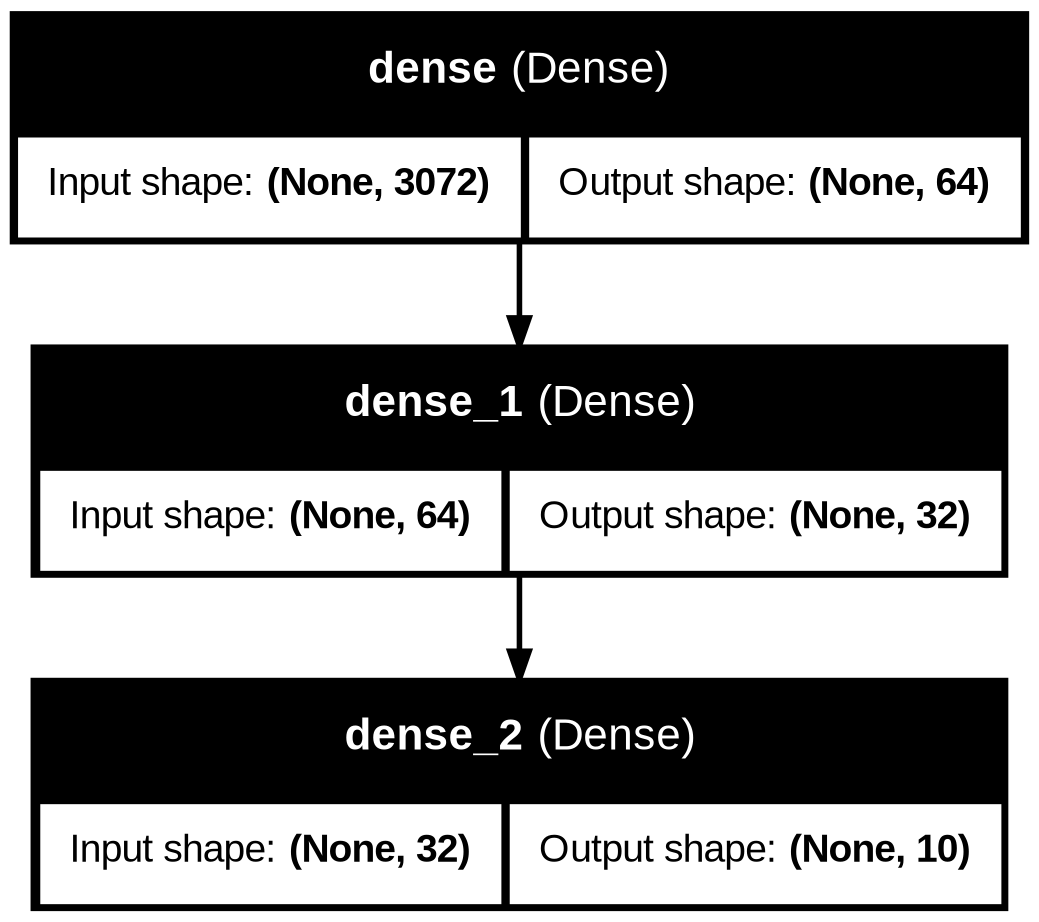

In [7]:
# Dense Neural Network with multiple hidden layers
model = Sequential()

model.add(Dense(64, activation='relu', input_shape=(dim,)))
model.add(Dense(32, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))

model.compile(loss='categorical_crossentropy',
              optimizer=RMSprop(),
              metrics=['accuracy'])

model.summary()
# Param calculation in each layer = input * output + output bias
# Input images = 32 * 32 * 3 = 3072
# dense Params =  = 3072 * 64 + 64 = 196672
# dense_1 params = 64 * 32 + 32 = 30 = 2080
# dense_2 params = 32 * 10 + 10 = 30 = 330

plot_model(model, show_shapes=True, show_layer_names=True)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.2321 - loss: 2.0894 - val_accuracy: 0.2774 - val_loss: 1.9969
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3110 - loss: 1.8952 - val_accuracy: 0.3284 - val_loss: 1.8536
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3402 - loss: 1.8259 - val_accuracy: 0.3045 - val_loss: 1.9246
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3624 - loss: 1.7828 - val_accuracy: 0.3754 - val_loss: 1.7292
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3744 - loss: 1.7489 - val_accuracy: 0.3430 - val_loss: 1.8456
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3808 - loss: 1.7256 - val_accuracy: 0.3790 - val_loss: 1.7172
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3923 - loss: 1.7019 - val_accuracy: 0.3804 - val_loss: 1.7085
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3963 - loss: 1.6825 - val_accuracy: 0

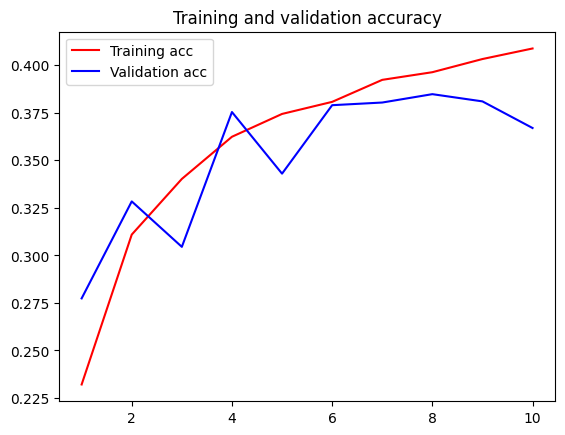

Test loss: 1.7772963047027588
Test accuracy: 0.373199999332428
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [8]:
#@title Train the Neural Network with the input number of epochs

epochs = 10 #@param {type:"integer"}

# stochastic gradient descent
batch_size = 128

# Set aside the first 10,000 samples as the validation set
val_size = 10000
x_valp = x_trainp[:val_size]
partial_x_trainp = x_trainp[val_size:]

y_valp = y_trainp[:val_size]
partial_y_trainp = y_trainp[val_size:]

history = model.fit(partial_x_trainp, partial_y_trainp,
                    batch_size=batch_size,
                    epochs=epochs,
                    verbose=1,
                    validation_data=(x_valp, y_valp))

# Plot the accuracy
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epoch = range(1, len(acc) + 1)

plt.plot(epoch, acc, 'r', label='Training acc')
plt.plot(epoch, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.show()


# Do the prediction on test set
score = model.evaluate(x_testp, y_testp, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

ans = model.predict(x_testp)

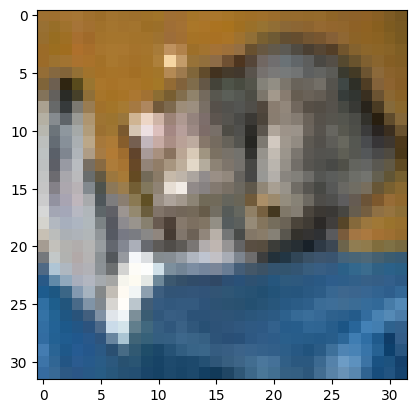

plane = 8.32
car   = 7.8
bird  = 25.04
cat   = 12.8
deer  = 1.01
dog   = 34.28
frog  = 8.04
horse = 0.11
ship  = 2.52
truck = 0.07
------------------
True Label: cat  


In [9]:
#@title Pick one sample from the testing data to verify the prediction

test_sample = 0 #@param {type:"integer"}

predictOneImage(x_test, y_test, ans, test_sample)


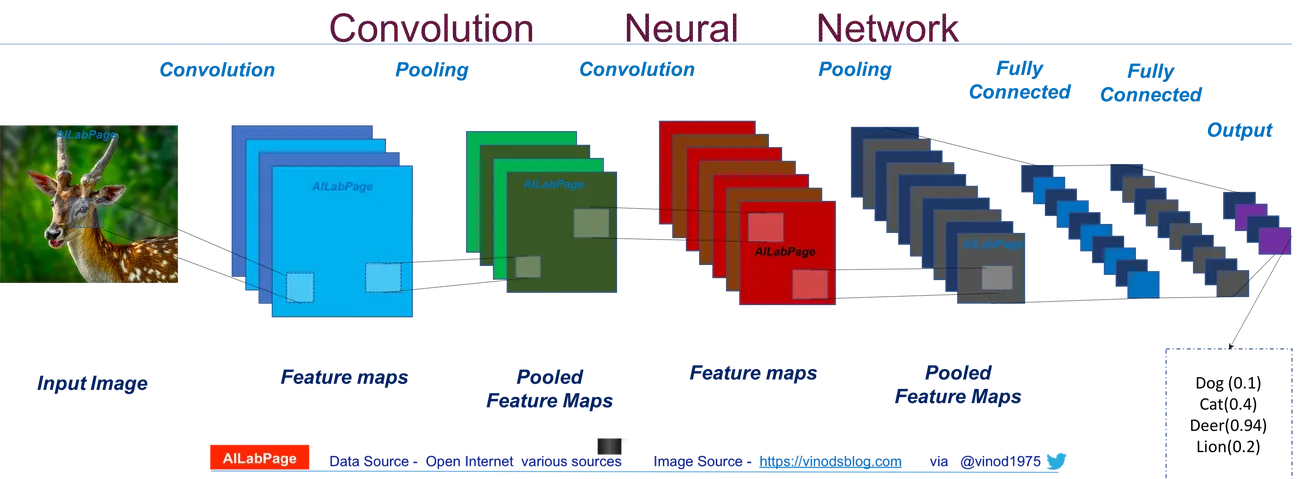

In [10]:
#@title Convert the input pixels to CNN neural network input vector format

# Use CNN and reshape the 32x32x3 pixels
# and normalize the number by 255

x_trainCnn = x_train.reshape(train_size, height, width, depth)
x_testCnn = x_test.reshape(test_size, height, width, depth)

x_trainCnn = x_trainCnn.astype('float32') / normalize
x_testCnn = x_testCnn.astype('float32') / normalize

print(x_trainCnn.shape[0], 'train samples')
print(x_testCnn.shape[0], 'test samples')

50000 train samples
10000 test samples


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

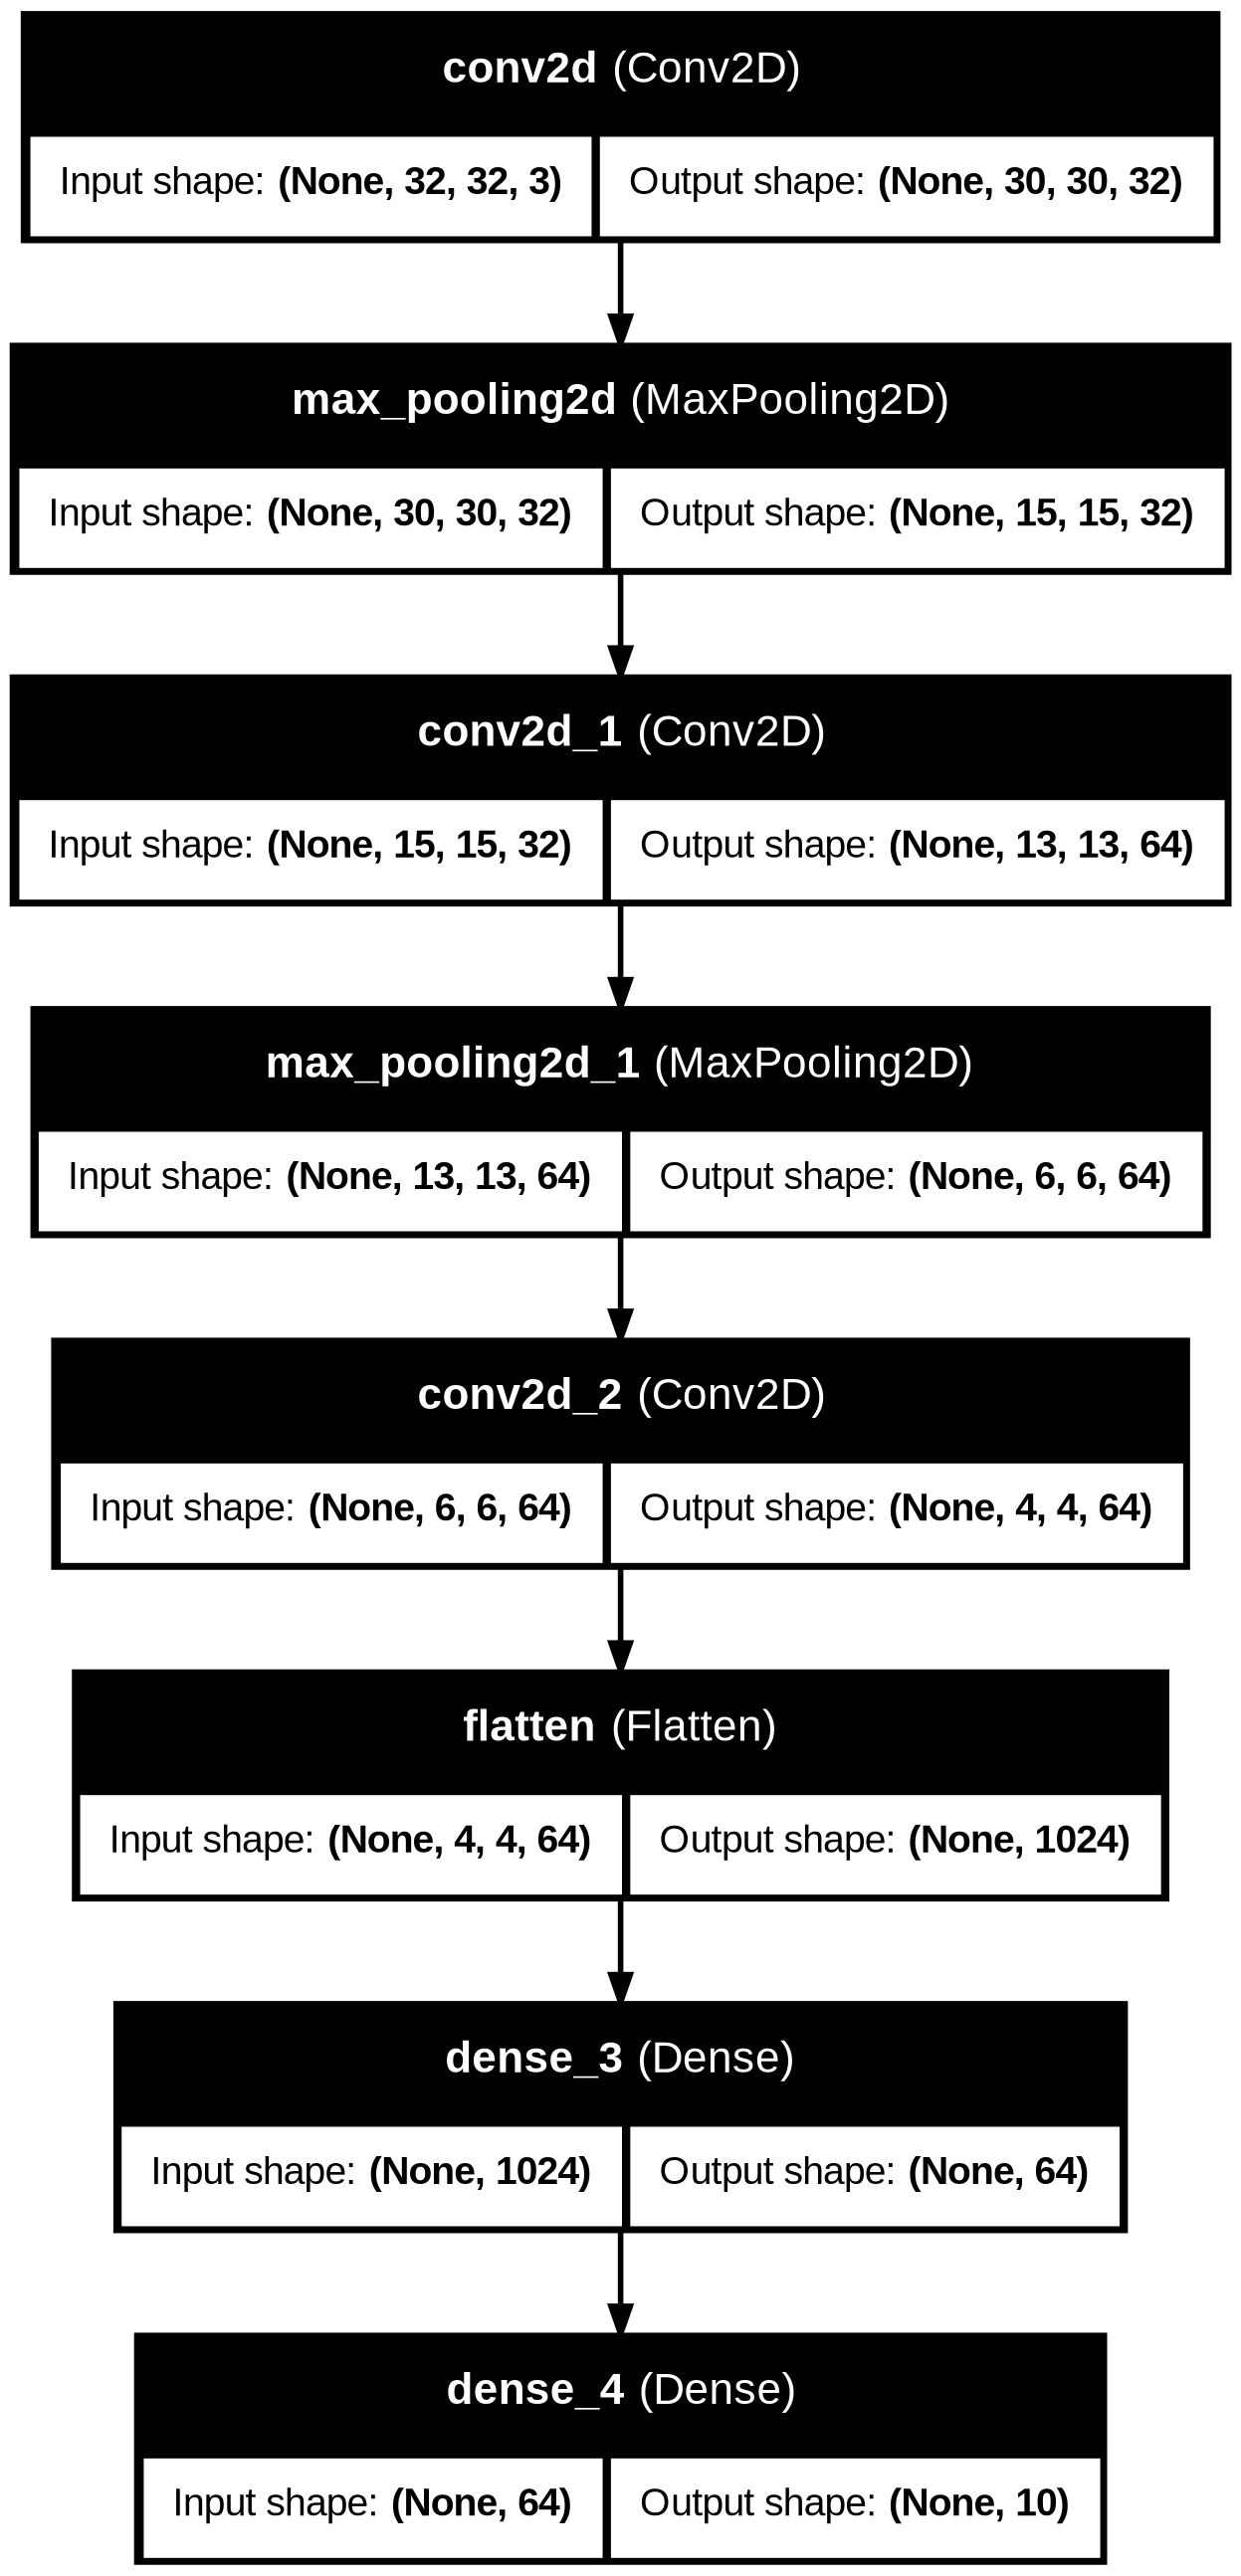

In [11]:
# Use CNN
cnn = Sequential()

# Filter = 32, Kernel_size = 3 * 3
cnn.add(Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
cnn.add(MaxPooling2D((2, 2)))
cnn.add(Conv2D(64, (3, 3), activation='relu'))
cnn.add(MaxPooling2D((2, 2)))
cnn.add(Conv2D(64, (3, 3), activation='relu'))

cnn.add(Flatten())
cnn.add(Dense(64, activation='relu'))
cnn.add(Dense(10, activation='softmax'))

cnn.compile(loss='categorical_crossentropy',
              optimizer=RMSprop(),
              metrics=['accuracy'])


cnn.summary()
# Pooling Layer: There are no parameters you could learn in pooling layer. This layer is just used to reduce the image dimension size.
# Conv layer parameters:  (n * m * l + 1) * k,  where n * m is the kernel_size, l is input filter, k is the output filter
# conv2d = (3 * 3 * 3 + 1) * 32 = 896
# conv2d_1 = (3 * 3 * 32 + 1) * 64 = 18496
# conv2d_2 = (3 * 3 * 64 + 1) * 64 = 36928

plot_model(cnn, show_shapes=True, show_layer_names=True)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 24ms/step - accuracy: 0.3172 - loss: 1.8816 - val_accuracy: 0.3828 - val_loss: 1.6823
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4649 - loss: 1.5031 - val_accuracy: 0.4863 - val_loss: 1.4284
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5317 - loss: 1.3299 - val_accuracy: 0.5360 - val_loss: 1.2980
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5766 - loss: 1.2040 - val_accuracy: 0.5530 - val_loss: 1.2898
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6140 - loss: 1.1067 - val_accuracy: 0.6121 - val_loss: 1.0989
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6412 - loss: 1.0237 - val_accuracy: 0.6208 - val_loss: 1.0972
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6668 - loss: 0.9544 - val_accuracy: 0.6442 - val_loss: 1.0245
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6867 - loss: 0.8976 - val_accuracy: 

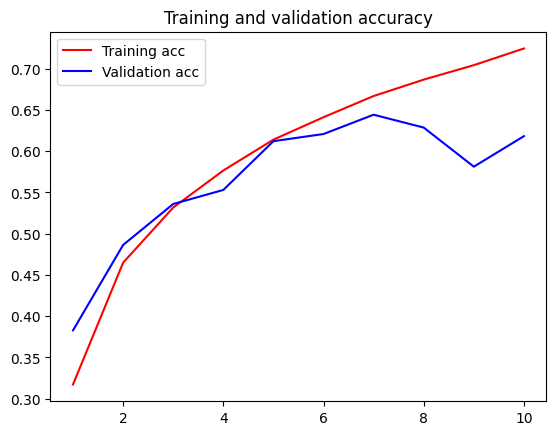

Test loss: 1.2032923698425293
Test accuracy: 0.605400025844574
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [12]:
#@title Train the Neural Network with the input number of epochs

epochs = 10 #@param {type:"integer"}

# Set aside the some samples as the validation set
x_valCnn = x_trainCnn[:val_size]
partial_x_trainCnn = x_trainCnn[val_size:]


history = cnn.fit(partial_x_trainCnn, partial_y_trainp,
                    batch_size=batch_size,
                    epochs=epochs,
                    verbose=1,
                    validation_data=(x_valCnn, y_valp))

# Plot the accuracy
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epoch = range(1, len(acc) + 1)

plt.plot(epoch, acc, 'r', label='Training acc')
plt.plot(epoch, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.show()

# Do the prediction on test set
score = cnn.evaluate(x_testCnn, y_testp, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

cnnAns = cnn.predict(x_testCnn)

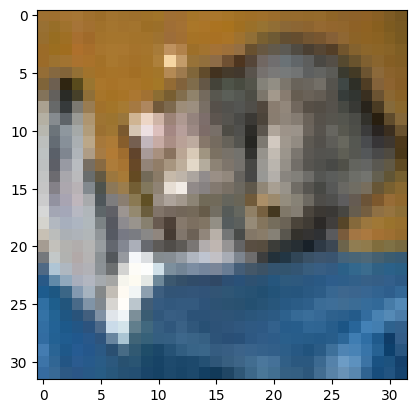

plane = 0.36
car   = 0.02
bird  = 6.29
cat   = 66.45
deer  = 0.08
dog   = 20.5
frog  = 5.52
horse = 0.37
ship  = 0.37
truck = 0.03
------------------
True Label: cat  


In [13]:
#@title Pick one sample from the testing data to verify the prediction

test_sample = 0 #@param {type:"integer"}
predictOneImage(x_test, y_test, cnnAns, test_sample)

# Use pre-trained VGG Imagenet CNN layers
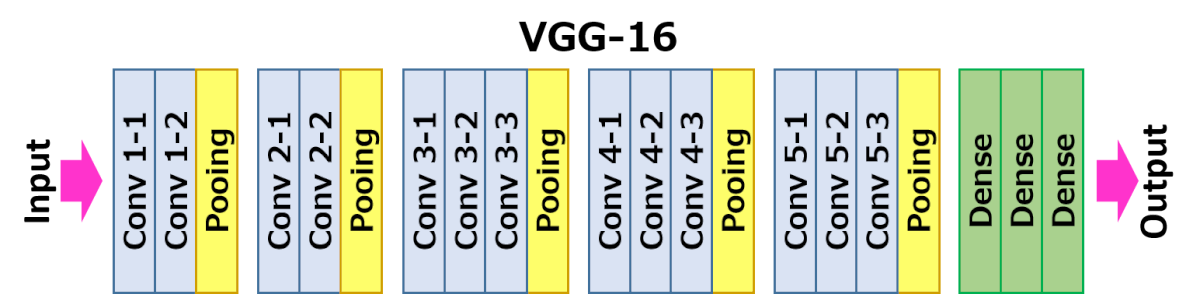

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 7,079,424 (27.01 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

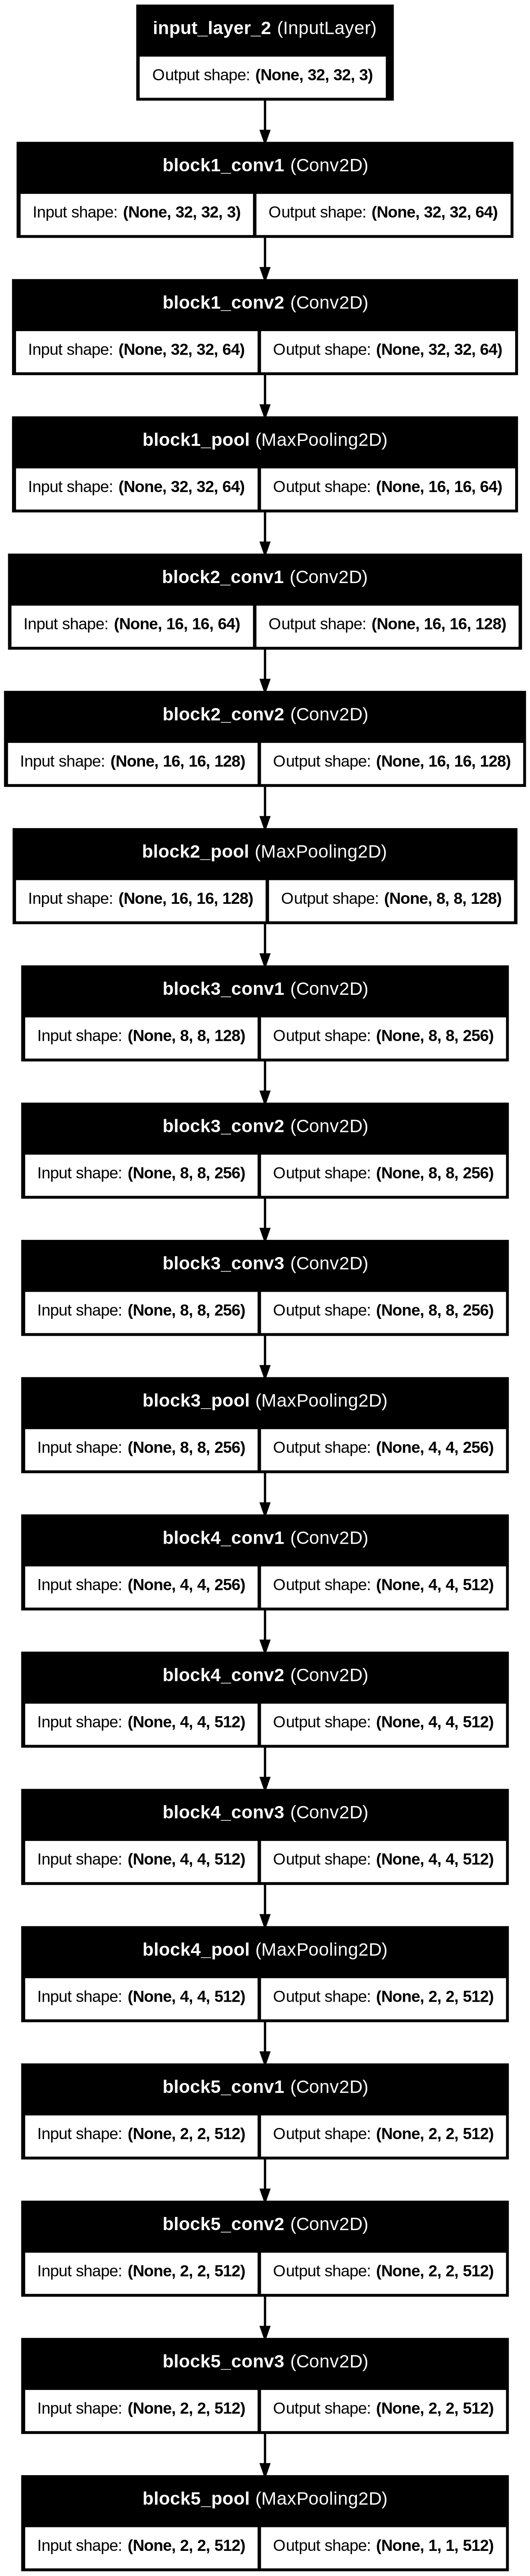

In [14]:
#@title Load the pre-trained VGG Imagenet CNN layers

# include_top=False: doesn't include the densely connected classifier layers on top of the network
conv_base = VGG16(weights='imagenet', include_top=False, input_shape=(height, width, depth))
conv_base.trainable = True

# Fine-tune the last 3 convolutional layers (i.e. block5)
# Usually fine-tune the last few convolutional layers as it's more higher level (abstract) features to the problem
# while the first few layers are more generic and re-usable features
for layer in conv_base.layers:
  if layer.name[:6] != 'block5':
    layer.trainable = False

conv_base.summary()

plot_model(conv_base, show_shapes=True, show_layer_names=True)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,748,170 (56.26 MB)

 Trainable params: 7,112,906 (27.13 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

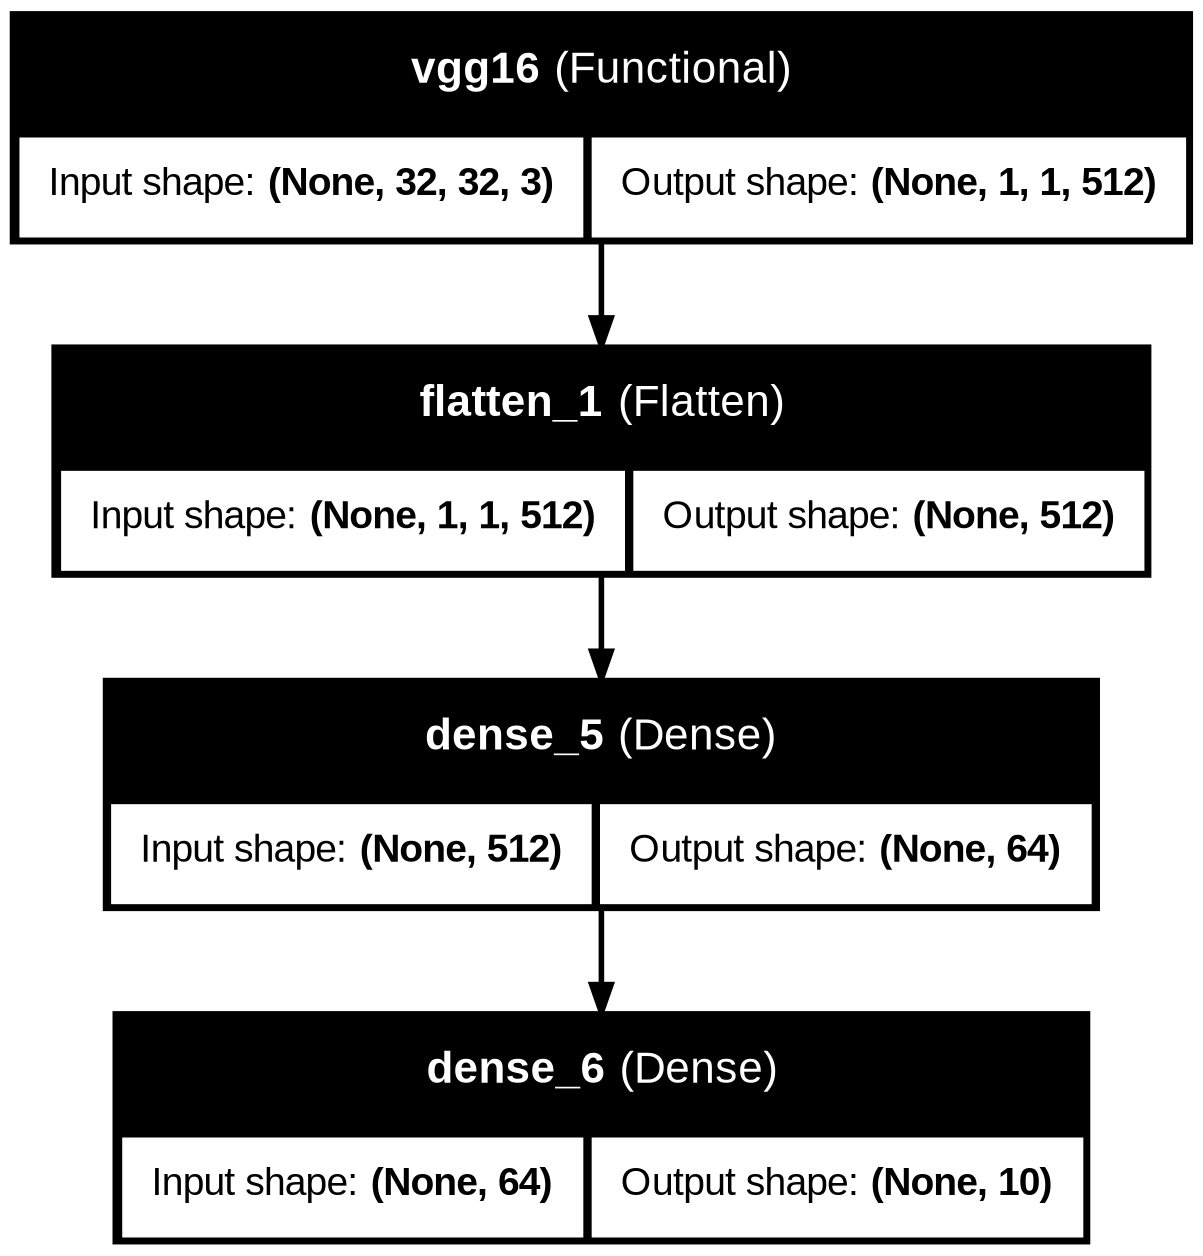

In [15]:
# Use CNN with pre-trained VGG layer
pModel = Sequential()

pModel.add(conv_base)
pModel.add(Flatten())
pModel.add(Dense(64, activation='relu'))
pModel.add(Dense(10, activation='softmax'))

pModel.compile(loss='categorical_crossentropy',
              optimizer=RMSprop(),
              metrics=['accuracy'])

pModel.summary()

plot_model(pModel, show_shapes=True, show_layer_names=True)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.4925 - loss: 1.4809 - val_accuracy: 0.5994 - val_loss: 1.2132
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.6692 - loss: 0.9785 - val_accuracy: 0.6593 - val_loss: 1.0267
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.7154 - loss: 0.8339 - val_accuracy: 0.6832 - val_loss: 0.9476
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.7472 - loss: 0.7325 - val_accuracy: 0.6832 - val_loss: 0.9248
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.7734 - loss: 0.6578 - val_accuracy: 0.7062 - val_loss: 0.9409
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.7954 - loss: 0.5843 - val_accuracy: 0.7402 - val_loss: 0.8068
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.8202 - loss: 0.5151 - val_accuracy: 0.7142 - val_loss: 0.9337
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8404 - loss: 0.4548 - val_acc

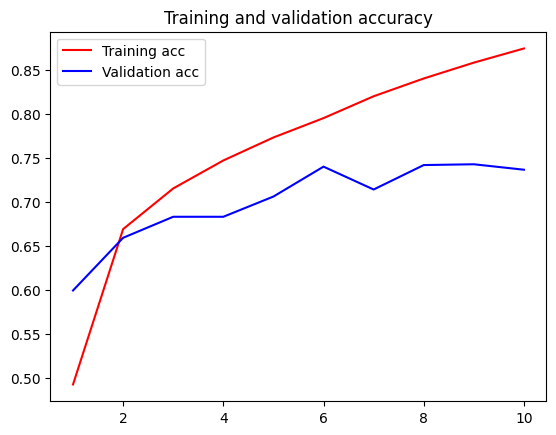

Test loss: 1.0415517091751099
Test accuracy: 0.7213000059127808
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


In [16]:
#@title Train the Neural Network with the input number of epochs

epochs = 10 #@param {type:"integer"}

history = pModel.fit(partial_x_trainCnn, partial_y_trainp,
                    batch_size=batch_size,
                    epochs=epochs,
                    verbose=1,
                    validation_data=(x_valCnn, y_valp))

# Plot the accuracy
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epoch = range(1, len(acc) + 1)

plt.plot(epoch, acc, 'r', label='Training acc')
plt.plot(epoch, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.show()

# Do the prediction on test set
score = pModel.evaluate(x_testCnn, y_testp, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

pAns = pModel.predict(x_testCnn)

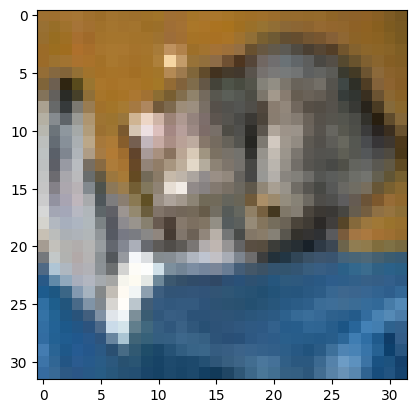

plane = 0.0
car   = 0.01
bird  = 0.0
cat   = 86.99
deer  = 0.0
dog   = 12.93
frog  = 0.0
horse = 0.0
ship  = 0.0
truck = 0.07
------------------
True Label: cat  


In [17]:
#@title Pick one sample from the testing data to verify the prediction

test_sample = 0 #@param {type:"integer"}

predictOneImage(x_test, y_test, pAns, test_sample)